# 04 · Predicting case duration

Week 4 models on `model_maharashtra.parquet` (cases filed 2012–2018 with court congestion
features, observation ending 2018-12-31; D-014, D-016). Design (D-015):

- **Time-based split.** Train on 2012–2015 filings, test on 2016–2018 filings. Filing year is not a
  feature: a model would have to extrapolate it. Congestion features carry the changing load.
- **Models.** (1) KM curve of the case category (baseline), (2) Cox stratified by category,
  (3) XGBoost AFT (log-normal), (4) XGBoost Cox with a Breslow baseline.
- **Metrics on a fixed 50k test sample, up to 2 years.** Uno's IPCW C-index (ranking by restricted
  mean survival time), integrated Brier score over 30–730 days, and Brier at 1 and 2 years. The
  censoring weights come from the test set, which is much more censored than the training set.
  Uno's C is quadratic in sksurv, so 50k is the practical size (standard error about 0.002).

In [1]:
import gc
import time
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import numpy as np
import pandas as pd
from sksurv.metrics import brier_score

from court_delay import models as M
from court_delay.config import DATA, ROOT

FIG = ROOT / "reports" / "figures"
OUT = DATA / "models" / "eval"
OUT.mkdir(parents=True, exist_ok=True)

# Reference palette (dataviz skill), light mode. Blue/orange/aqua validated for CVD; aqua is below
# 3:1 contrast, so every line is direct-labelled and the metrics are also given as a table.
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#a9a8a3"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "lines.linewidth": 2, "legend.frameon": False,
})
NAMES = {"baseline": "KM by category", "cox": "Cox (stratified)", "xgb_aft": "XGBoost AFT",
         "xgb_cox": "XGBoost Cox"}
COLORS = {"baseline": MUTED, "cox": BLUE, "xgb_aft": AQUA, "xgb_cox": ORANGE}


def finish(fig, name):
    fig.text(0.01, -0.03, "Source: Development Data Lab e-Courts data, Maharashtra. Trained on 2012–2015 "
             "filings, tested on a 50k sample of 2016–2018 filings; observation ends 2018-12-31.",
             fontsize=7.5, color=INK2)
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

In [2]:
df = M.load()
train, test = M.split(df)
del df
summary = pd.concat([d.groupby("year").agg(
    cases=("event", "size"), decided=("event", "mean"),
    median_queue_ratio=("queue_ratio", "median")) for d in (train, test)])
summary["decided"] = summary["decided"].map("{:.1%}".format)
print(f"train {len(train):,} cases, test {len(test):,} cases")
summary

train 4,369,304 cases, test 3,926,570 cases


,cases,decided,median_queue_ratio
year,,,
2012,962809,87.0%,1.257331
2013,1036684,82.2%,1.227001
2014,1113205,77.4%,1.208583
2015,1256606,72.4%,1.128429
2016,1246120,62.6%,1.137297
2017,1309894,52.5%,1.181463
2018,1370556,37.8%,1.122099


In [3]:
SEED = 0
ev = test.sample(50_000, random_state=SEED).reset_index(drop=True)      # evaluation sample
fit = train.sample(1_500_000, random_state=SEED + 1)                     # boosting train
val = train.drop(fit.index).sample(200_000, random_state=SEED + 2)       # early stopping
cox_fit = fit.iloc[:200_000].copy()                                             # lifelines Cox
models, fit_secs = {}, {}

def timed(name, model, *args):
    t = time.time()
    models[name] = model.fit(*args)
    fit_secs[name] = time.time() - t
    print(f"{NAMES[name]}: fitted in {fit_secs[name]:.0f}s")

timed("baseline", M.KMBaseline(), train)
del train, test          # keep only the samples: other apps leave this machine ~3 GB of memory
gc.collect()
timed("cox", M.CoxModel(), cox_fit)

KM by category: fitted in 1s


Cox (stratified): fitted in 26s


Cox coefficients for the congestion features (standardised, so each hazard ratio is per one
standard deviation). A hazard ratio below 1 means slower decisions.

In [4]:
hr = models["cox"].cph.summary.loc[M.NUMERIC, ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%"]]
hr.round(3)

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%
covariate,,,
log_inflow,1.933,1.875,1.993
log_backlog,0.483,0.469,0.497
queue_ratio,1.012,0.999,1.025
clearance_1y,1.083,1.074,1.092
clearance_missing,0.980,0.974,0.985
is_criminal,1.000,0.871,1.149
court_system,1.058,1.034,1.083


In [5]:
timed("xgb_cox", M.XGBCox(rounds=1500), fit, val)
print("best iteration", models["xgb_cox"].booster.best_iteration)

XGBoost Cox: fitted in 314s
best iteration 866


The AFT error scale σ is fixed in XGBoost, so it is tuned first on a small sample: the prototype
kept improving from σ = 0.8 to 1.8.

In [6]:
small, small_val = fit.iloc[:300_000], val.iloc[:100_000]
sigma_loss = {}
for s in (1.8, 2.4, 3.0):
    m = M.XGBAFT(sigma=s, rounds=300).fit(small, small_val)
    sigma_loss[s] = m.booster.best_score
print({k: round(v, 4) for k, v in sigma_loss.items()})
SIGMA = min(sigma_loss, key=sigma_loss.get)
timed("xgb_aft", M.XGBAFT(sigma=SIGMA, rounds=1500), fit, val)
print("sigma", SIGMA, "best iteration", models["xgb_aft"].booster.best_iteration)

{1.8: 5.8078, 2.4: 5.8279, 3.0: 5.9048}


XGBoost AFT: fitted in 298s
sigma 1.8 best iteration 1499


In [7]:
surv = {k: m.predict_survival(ev) for k, m in models.items()}
metrics = pd.DataFrame({NAMES[k]: M.evaluate(s, ev) for k, s in surv.items()}).T
metrics["fit_seconds"] = [fit_secs[k] for k in surv]
metrics.to_csv(ROOT / "reports" / "model_metrics.csv")
metrics.round(4)

,c_uno,c_harrell,ibs,brier_1y,brier_2y,horizon_days,fit_seconds
KM by category,0.6509,0.6569,0.1999,0.2085,0.2069,730.0,0.8703
Cox (stratified),0.6919,0.7054,0.1882,0.1954,0.1985,730.0,25.6443
XGBoost Cox,0.6993,0.7114,0.1883,0.1946,0.1965,730.0,314.1621
XGBoost AFT,0.6957,0.7143,0.1967,0.2064,0.2078,730.0,298.2448


Metrics by test filing year. Later filings have shorter follow-up (2018 filings at most 12
months, 2017 filings 24), so their metrics cover shorter horizons and are not comparable across years.

In [8]:
rows = []
for year, g in ev.groupby("year"):
    idx = g.index.to_numpy()
    for k, s in surv.items():
        m = M.evaluate(s[idx], g)
        rows.append({"year": year, "model": NAMES[k], "c_uno": m["c_uno"], "ibs": m["ibs"]})
by_year = pd.DataFrame(rows).pivot(index="model", columns="year")
by_year.round(3)

c_uno                  ibs              
year               2016   2017   2018   2016   2017   2018
model                                                     
Cox (stratified)  0.696  0.687  0.702  0.185  0.190  0.184
KM by category    0.664  0.646  0.649  0.193  0.202  0.200
XGBoost AFT       0.705  0.692  0.700  0.194  0.198  0.189
XGBoost Cox       0.712  0.691  0.699  0.181  0.191  0.188

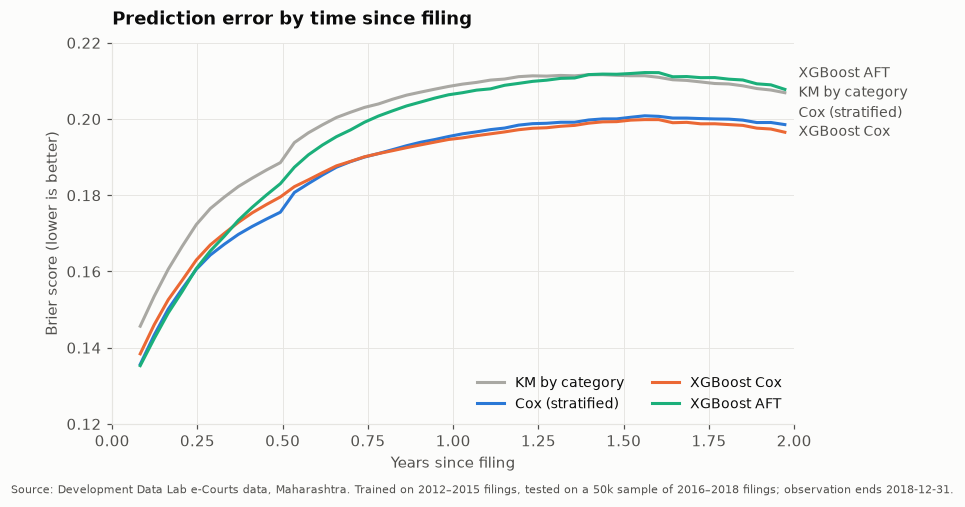

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
idx = np.searchsorted(M.GRID, M.BRIER_TIMES)
y = M.surv_array(ev)
ends = {}
for k, s in surv.items():
    _, b = brier_score(y, y, s[:, idx], M.BRIER_TIMES)
    ax.plot(M.BRIER_TIMES / 365, b, color=COLORS[k])
    ends[k] = b[-1]
gap, prev = 0.005, -np.inf                     # spread end labels so they never overlap
for k in sorted(ends, key=ends.get):
    prev = max(ends[k], prev + gap)
    ax.annotate(NAMES[k], (M.BRIER_TIMES[-1] / 365, ends[k]), xytext=(M.BRIER_TIMES[-1] / 365 + 0.04, prev),
                textcoords="data", va="center", fontsize=9, color=INK2, annotation_clip=False)
ax.set_xlim(0, 2)
ax.set_ylim(0.12, 0.22)                         # lines, not bars: a zoomed axis is fine
ax.set_xlabel("Years since filing")
ax.set_ylabel("Brier score (lower is better)")
ax.set_title("Prediction error by time since filing")
ax.legend([plt.Line2D([], [], color=COLORS[k]) for k in surv], [NAMES[k] for k in surv],
          loc="lower right", ncol=2, fontsize=9)
finish(fig, "11_brier_over_time")

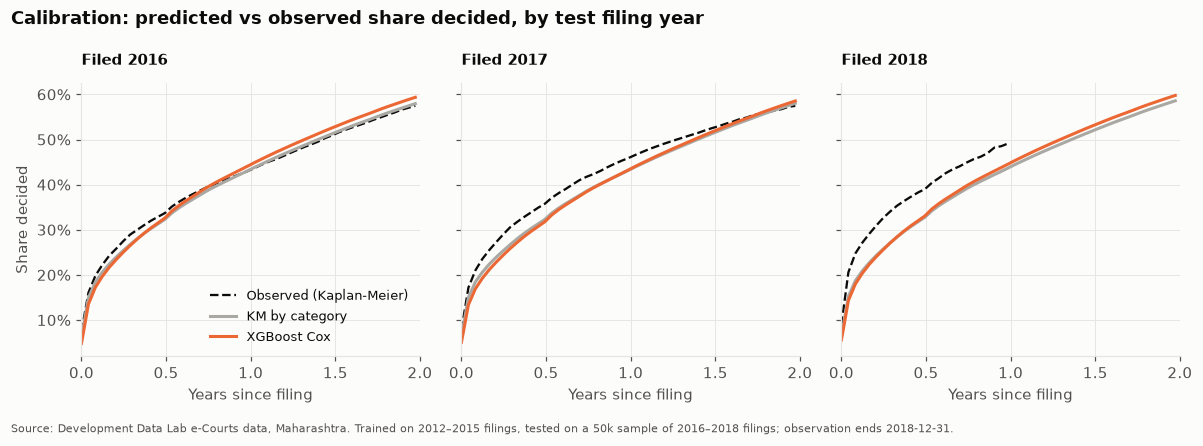

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
for ax, (year, g) in zip(axes, ev.groupby("year")):
    i = g.index.to_numpy()
    obs = M.km_curve(g["duration_days"], g["event"], M.GRID[M.GRID <= g["duration_days"].max()])
    ax.plot(M.GRID[:len(obs)] / 365, 1 - obs, color=INK, linestyle="--", linewidth=1.5)
    for k in ("baseline", "xgb_cox"):
        ax.plot(M.GRID / 365, 1 - surv[k][i].mean(axis=0), color=COLORS[k])
    ax.set_title(f"Filed {year}", fontsize=10)
    ax.set_xlim(0, 2)
    ax.set_xlabel("Years since filing")
    ax.yaxis.set_major_formatter(mt.PercentFormatter(1))
axes[0].set_ylabel("Share decided")
axes[0].legend([plt.Line2D([], [], color=INK, linestyle="--", linewidth=1.5)] +
               [plt.Line2D([], [], color=COLORS[k]) for k in ("baseline", "xgb_cox")],
               ["Observed (Kaplan-Meier)", NAMES["baseline"], NAMES["xgb_cox"]], loc="lower right",
               fontsize=8.5)
fig.suptitle("Calibration: predicted vs observed share decided, by test filing year",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
finish(fig, "12_calibration_by_year")

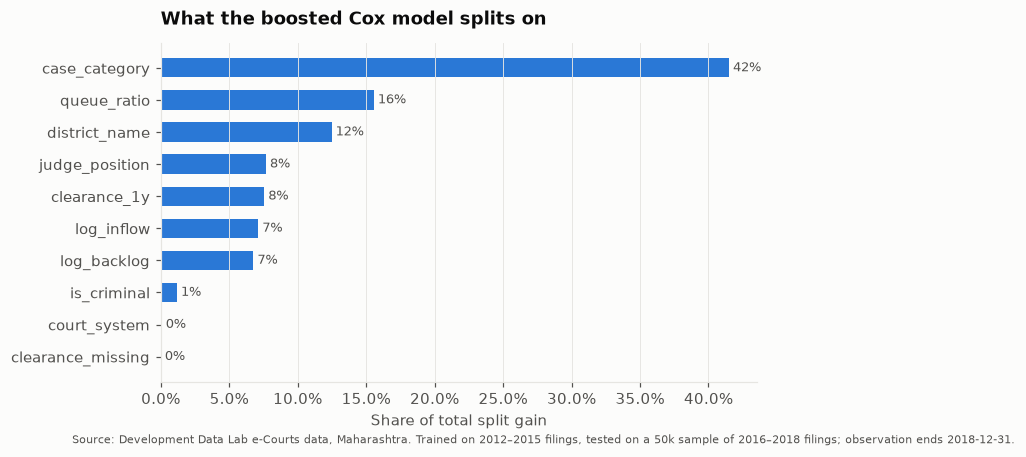

In [11]:
gain = pd.Series(models["xgb_cox"].booster.get_score(importance_type="total_gain"))
gain = (gain / gain.sum()).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(gain.index, gain.values, color=BLUE, height=0.6)
for i, v in enumerate(gain.values):
    ax.text(v, i, f" {v:.0%}", va="center", fontsize=8.5, color=INK2)
ax.xaxis.set_major_formatter(mt.PercentFormatter(1))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of total split gain")
ax.set_title("What the boosted Cox model splits on")
finish(fig, "13_xgb_importance")

In [12]:
models["xgb_cox"].save(OUT)
print("saved to", OUT)

saved to A:\VS CODE PROGRAM\court-case-predictor\data\models


## Summary

| model | Uno's C | integrated Brier (30–730 d) |
|---|---|---|
| KM by category (baseline) | 0.651 | 0.200 |
| Cox, stratified by category | 0.692 | **0.188** |
| XGBoost AFT | 0.696 | 0.197 |
| **XGBoost Cox** | **0.699** | **0.188** |

- **Court, district and congestion features add about 0.05 C-index** over case type alone and
  cut prediction error by 6%.
- **Boosting adds little over a linear Cox model:** 0.699 vs 0.692 C, equal Brier. XGBoost Cox is
  kept as the main model (best ranking, and SHAP in `05_shap`).
- **AFT ranks well but is poorly calibrated:** one log-normal shape cannot fit same-day closures
  and multi-year cases together.
- **Congestion is the second most used block** after case category (about 38% of split gain).
- **Calibration drifts:** 2016 filings are well calibrated, but 2017–2018 filings are decided
  faster in their first year than predicted (about 6 points more decided at 6 months for 2018),
  matching the ~2% per year speed-up in `03_survival`. A model trained only on older filings
  misses it.